# Figure S16: Ancestry enrichment across allele frequencies

Ancestry enrichment and cross-population allele sharing across allele-frequency bins.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig2_data](../../preparation/Fig2/build.R): Prepare current frequency bins, unique-variant ancestry tests, consequence-priority aFC data and regressions, cumulative aFC summaries, outlier statistics from contingency counts, protein-coding medians, and S16 ancestry bins.
- [fig2_notebook](../../preparation/Fig2/connect_notebook.R): Connect newly prepared A-F data, fitted regression annotations, cumulative percentages, and S16 bins/rolling curve to the exact plot-object files read by current notebooks.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved REM display

Restore S16 from the current saved ancestry-enrichment plot. The source already displays OTH as REM. This notebook does not rerun ancestry enrichment tests or estimate the rolling summaries again.


In [2]:
saved <- readRDS(paper_file("Supplemental Figures/01_Supplemental_drafts/Figure2_ancestry_enrichment_REM/Supplemental_Figure_S16_ancestry_enrichment_REM.rds"))
stopifnot(inherits(saved, "ggplot"),
          all(c("af_bin", "n_enriched", "total_variants", "prop", "x") %in% names(saved$data)),
          all(dplyr::between(saved$data$prop, 0, 1)))


## Restore the ancestry-frequency curves

Colored curves show ancestry-enriched variant proportions in saved frequency bins. The additional curve shows variants with nonzero frequency in all seven groups. Its saved rolling mean is displayed with the original unconstrained LOESS layer, which can exceed 100%. The smooth curve is a visual guide. No enrichment test is repeated.


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'

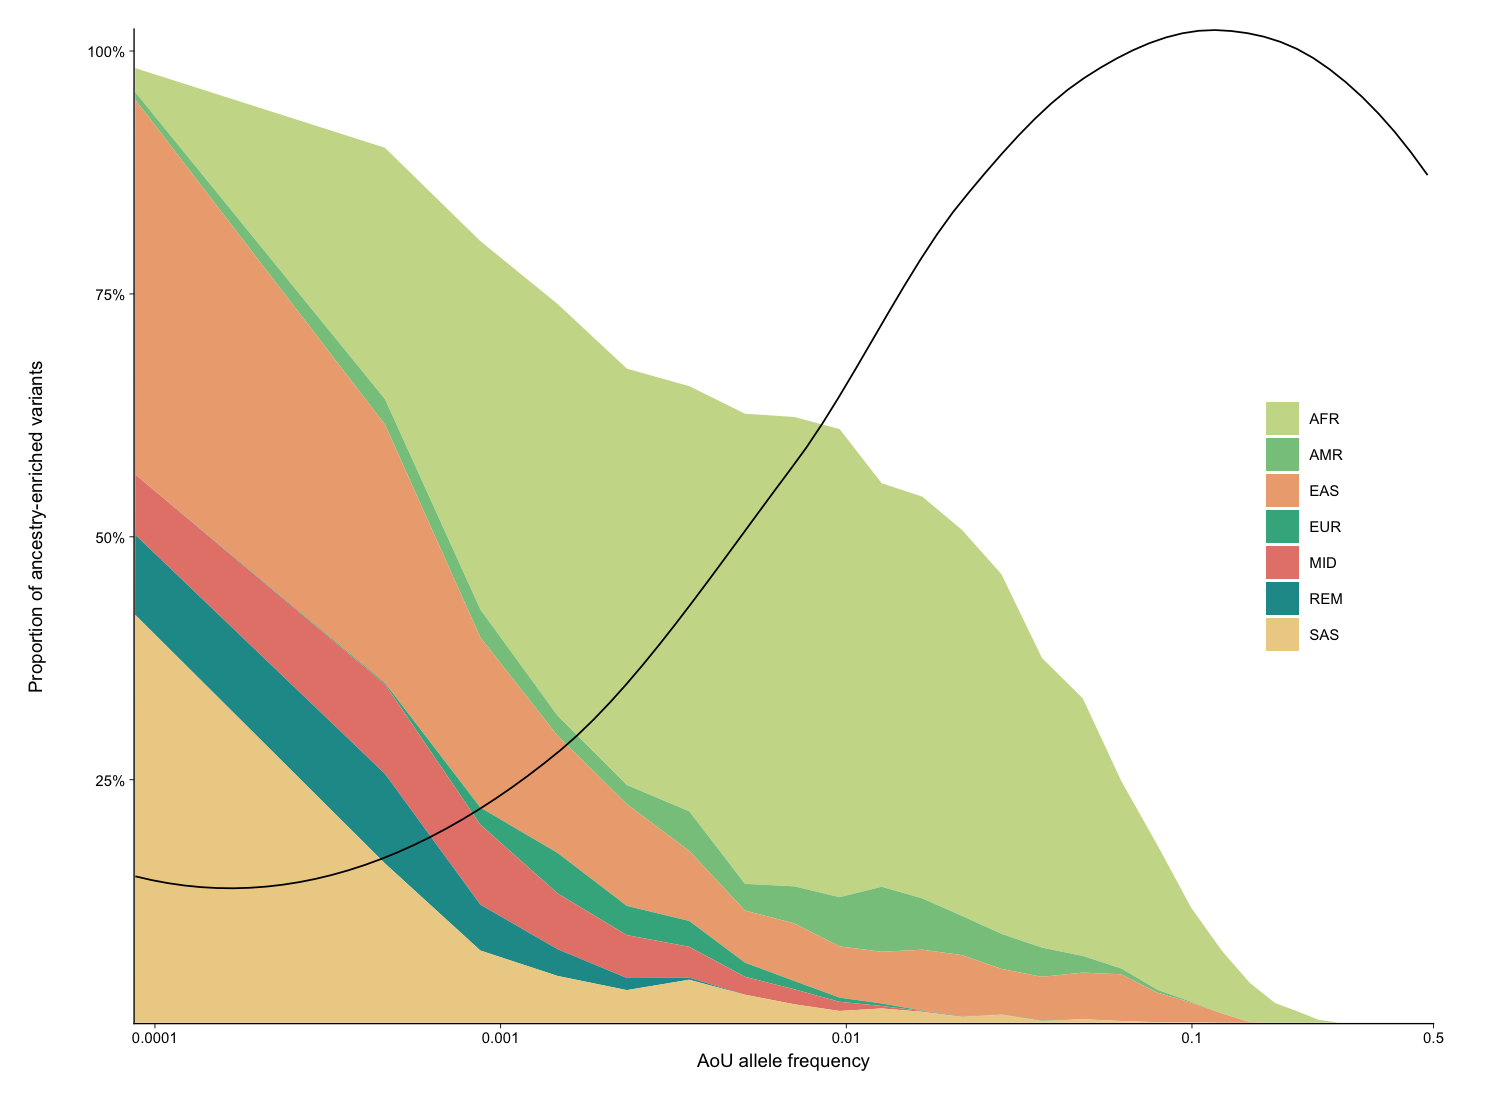

In [3]:
figure <- saved + labs(title = NULL, subtitle = NULL)
print(figure)


## Save aggregate outputs

Save the figure and frequency-bin counts. These are aggregate variant counts. REM is a display label for the source OTH category, not a new population estimate.


In [4]:
save_plot(figure, "supplements/S16", 184, 125)
readr::write_tsv(saved$data %>% select(af_bin, gvs_max_subpop, n_enriched, total_variants, prop, x) %>%
                   mutate(gvs_max_subpop = recode(as.character(gvs_max_subpop), OTH = "REM")),
                 output_file("supplements/S16_frequency_bins.tsv"))


Export aggregate plot: supplements/S16


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'